# How well do jobs and skills pay for Data Analysts?

**Methodology**

1. Evaluate median salary for top 6 data jobs
2. Find median salary of skills for Data Analyst
3. Visualize for highest paying skills and salary of top demand skills for Data Analyst

### Import Libraries and Data

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
import seaborn as sns
import ast

dataset = load_dataset("lukebarousse/data_jobs")
df = dataset['train'].to_pandas()
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

### Salary Distribution by Job Title

In [4]:
#Filter out job postings in the US and remove NaN values of salary
df_US = df[df['job_country'] == 'United States'].dropna(subset=['salary_year_avg'])

In [5]:
#Prepare job title list to visualize every single job title
job_titles = ['Data Analyst', 'Data Scientist', 'Data Engineer', 'Senior Data Analyst', 'Senior Data Scientist', 'Senior Data Engineer']


In [6]:
#Selecting main roles in Data field and aggregate them by median yearly salary
df_role_main = df_US[df_US['job_title_short'].isin(job_titles)]
job_order = df_role_main.groupby('job_title_short')['salary_year_avg'].median().sort_values(ascending=False).index
job_order

Index(['Senior Data Scientist', 'Senior Data Engineer', 'Data Scientist',
       'Data Engineer', 'Senior Data Analyst', 'Data Analyst'],
      dtype='str', name='job_title_short')

### Plot distributions of Salary 

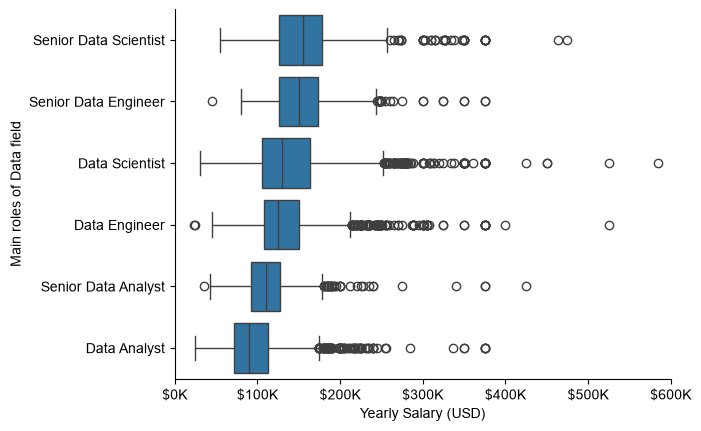

In [7]:
sns.boxplot(data = df_role_main, x = 'salary_year_avg', y = 'job_title_short', order = job_order)
sns.set_theme(style='ticks')
sns.despine()

#Set labels and title of graph
plt.xlabel('Yearly Salary (USD)')
plt.ylabel('Main roles of Data field')

#Set lim of xaxis
plt.xlim(0, 600000)

#Format xaxis into dollar currency 
ax = plt.gca()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${int(x/1000)}K'))
plt.show()


### Visualize Median Salary and Most Demanded Skills for Data Analysts

In [ ]:
#Filter out Data Analyst role and job postings in the US
df_DA_US = df[(df['job_title_short'] == 'Data Analyst') & (df['job_country'] == 'United States')]

#Remove NaN values of yearly salary average and explode job skills
df_DA_US = df_DA_US.dropna(subset=['salary_year_avg'])
df_DA_US= df_DA_US.explode('job_skills')

#Find top paying skills for Data Analyst
df_top_pay = df_DA_US.groupby('job_skills')['salary_year_avg'].agg(['count', 'median']).sort_values(by = 'median', ascending = False).head(10)
df_top_pay


,count,median
job_skills,,
dplyr,2,196250.0
bitbucket,3,189000.0
gitlab,3,186000.0
solidity,1,179000.0
hugging face,1,175000.0
couchbase,1,160515.0
ansible,1,159640.0
mxnet,2,149000.0
cassandra,6,148250.0


In [ ]:
#Find top in-demand skills for Data Analyst and sort value by their salary
df_count = df_DA_US.groupby('job_skills')['salary_year_avg'].agg(['count', 'median']).sort_values(by = 'count', ascending = False).head(10)
df_count = df_count.sort_values(by = 'median', ascending = False)
df_count

,count,median
job_skills,,
python,1431,97500.00
tableau,1364,92875.00
r,893,92500.00
sql server,286,92500.00
sql,2508,91000.00
sas,926,90000.00
power bi,838,90000.00
powerpoint,462,85000.00
excel,1808,84392.00


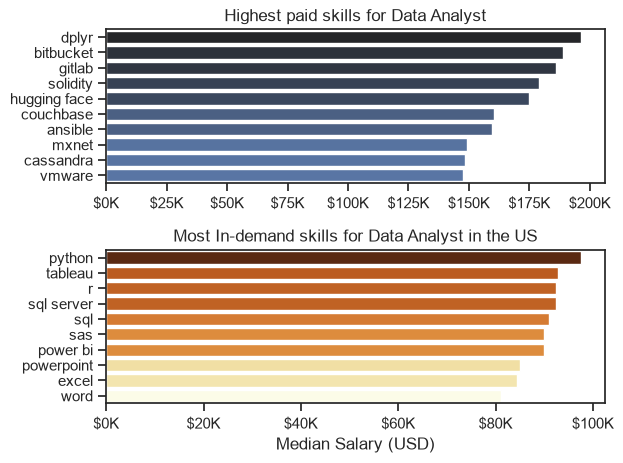

In [ ]:
fig, ax = plt.subplots(2,1)

#Top 10 highest paying skills for Data Analysts
sns.barplot(data=df_top_pay, x = 'median', y = 'job_skills', ax = ax[0],hue = 'median', palette='dark:b_r')
ax[0].legend().remove()
ax[0].set_title('Highest paid skills for Data Analyst')
ax[0].set_ylabel('')
ax[0].set_xlabel('')
ax[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${int(x/1000)}K'))

#Top 10 demanded skills for Data Analysts
sns.barplot(data=df_count, x = 'median', y = 'job_skills', ax = ax[1], hue = 'median', palette = 'YlOrBr')
ax[1].set_title('Most In-demand skills for Data Analyst in the US')
ax[1].set_xlabel('Median Salary (USD)')
ax[1].set_ylabel('')
ax[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${int(x/1000)}K'))
ax[1].legend().remove()

sns.set_theme(style='ticks')
fig.tight_layout()
plt.show()